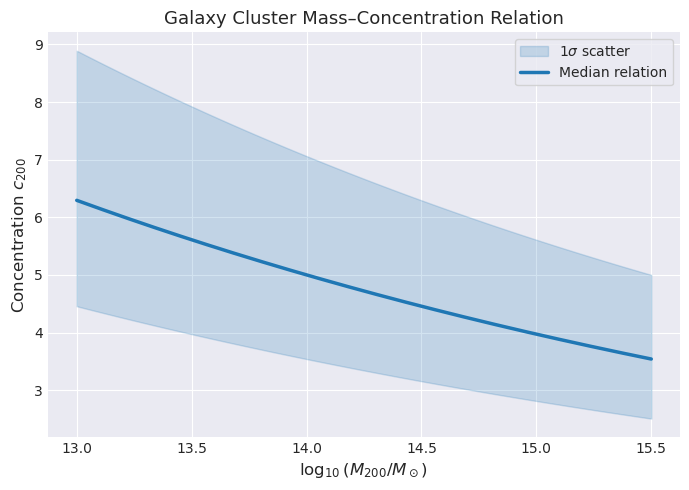

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# --- Toy mass–concentration relation parameters ---
# c(M) = c0 * (M / M_pivot)^alpha
c0 = 5.0
alpha = -0.1
M_pivot = 1e14  # solar masses (just a reference scale)

# Log10 mass range
logM = np.linspace(13, 15.5, 200)
M = 10**logM

# Median relation
c_med = c0 * (M / M_pivot)**alpha

# Assume a lognormal scatter in concentration: sigma in log10(c)
sigma_logc = 0.15  # ~35% scatter

# Compute upper/lower 1-sigma curves in linear space
logc_med = np.log10(c_med)
logc_up = logc_med + sigma_logc
logc_lo = logc_med - sigma_logc
c_up = 10**logc_up
c_lo = 10**logc_lo

# --- Plotting ---
plt.style.use("seaborn-v0_8-darkgrid")

fig, ax = plt.subplots(figsize=(7, 5))

# Shaded scatter region
ax.fill_between(
    logM, c_lo, c_up,
    color="tab:blue", alpha=0.2,
    label=r"$1\sigma$ scatter"
)

# Median curve
ax.plot(
    logM, c_med,
    color="tab:blue", lw=2.5,
    label="Median relation"
)

# Optional: a few mock data points scattered around the relation
rng = np.random.default_rng(42)
n_points = 60
logM_data = rng.uniform(13.1, 15.4, n_points)
M_data = 10**logM_data
logc_data = np.log10(
    c0 * (M_data / M_pivot)**alpha
) + rng.normal(0, sigma_logc, n_points)
c_data = 10**logc_data

# ax.scatter(
#     logM_data, c_data,
#     s=20, color="tab:gray", alpha=0.6,
#     edgecolor="none", label="Mock clusters"
# )

# Labels and cosmetics
ax.set_xlabel(r"$\log_{10}(M_{200} / M_\odot)$", fontsize=12)
ax.set_ylabel(r"Concentration $c_{200}$", fontsize=12)
ax.set_title("Galaxy Cluster Mass–Concentration Relation", fontsize=13)
ax.legend(frameon=True)
plt.tight_layout()
plt.show()


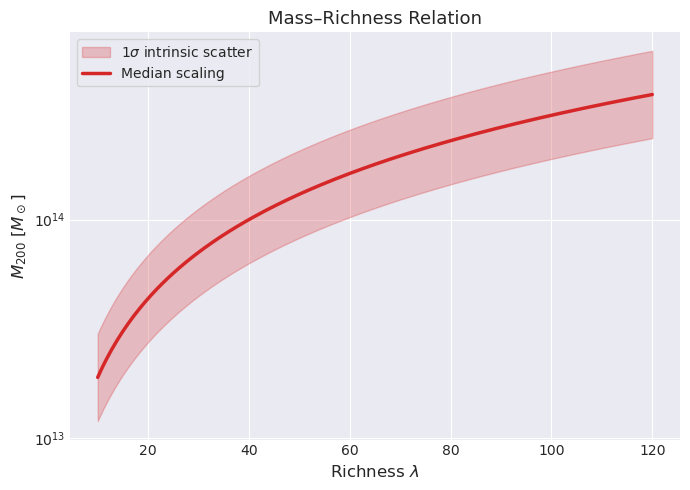

In [26]:
import numpy as np
import matplotlib.pyplot as plt

# --- Mass–Richness relation ---
# M(λ) = M0 * (λ / λ_pivot)^α
M0 = 1e14        # pivot mass
alpha = 1.2
lambda_pivot = 40

# Richness range
lam = np.linspace(10, 120, 200)

# Median relation
M_med = M0 * (lam / lambda_pivot)**alpha

# Lognormal scatter in mass (dex)
sigma_logM = 0.20   # ~60% scatter

logM_med = np.log10(M_med)
logM_up = logM_med + sigma_logM
logM_lo = logM_med - sigma_logM

M_up = 10**logM_up
M_lo = 10**logM_lo

# --- Plot ---
plt.style.use("seaborn-v0_8-darkgrid")
fig, ax = plt.subplots(figsize=(7, 5))

# Scatter band
ax.fill_between(
    lam, M_lo, M_up,
    color="tab:red", alpha=0.25,
    label=r"$1\sigma$ intrinsic scatter"
)

# Median curve
ax.plot(
    lam, M_med,
    color="tab:red", lw=2.5,
    label="Median scaling"
)

# Mock data points
rng = np.random.default_rng(9)
n_points = 60
lam_data = rng.uniform(12, 115, n_points)
logM_data = (
    np.log10(M0 * (lam_data / lambda_pivot)**alpha)
    + rng.normal(0, sigma_logM, n_points)
)
M_data = 10**logM_data

# ax.scatter(
#     lam_data, M_data,
#     s=22, color="tab:gray", alpha=0.6,
#     edgecolor="none", label="Mock clusters"
# )

# Labels
ax.set_xlabel(r"Richness $\lambda$", fontsize=12)
ax.set_ylabel(r"$M_{200}$ [$M_\odot$]", fontsize=12)
ax.set_yscale("log")
ax.set_title("Mass–Richness Relation", fontsize=13)
ax.legend(frameon=True)

plt.tight_layout()
plt.show()

In [19]:
from astropy.table import Table

clusters = Table(
    names=("cluster_id", "ra_deg", "dec_deg","redshift", "richness", "observable"),
    dtype=("U6", "f8", "f8","f8", "i4", "f8")
)

clusters.add_row(("CLJ001", 12.44, 32.18,0.175, 48, 0.73))
clusters.add_row(("CLJ002", 215.90, -1.22,0.181, 82, 0.41))
clusters.add_row(("CLJ003", 143.12, 5.77,0.239, 26, 0.12))
clusters.add_row(("CLJ004", 289.33, -17.55,0.201, 105, 0.88))
clusters.add_row(("CLJ005", 57.09, 11.03,0.255, 63, 0.55))
clusters.add_row(("CLJ006", 331.77, 22.49,0.177, 34, 0.29))
clusters.add_row(("CLJ007", 102.66, -6.14,0.160, 91, 0.94))



In [20]:
clusters

cluster_id,ra_deg,dec_deg,redshift,richness,observable
str6,float64,float64,float64,int32,float64
CLJ001,12.44,32.18,0.175,48,0.73
CLJ002,215.9,-1.22,0.181,82,0.41
CLJ003,143.12,5.77,0.239,26,0.12
CLJ004,289.33,-17.55,0.201,105,0.88
CLJ005,57.09,11.03,0.255,63,0.55
CLJ006,331.77,22.49,0.177,34,0.29
CLJ007,102.66,-6.14,0.16,91,0.94


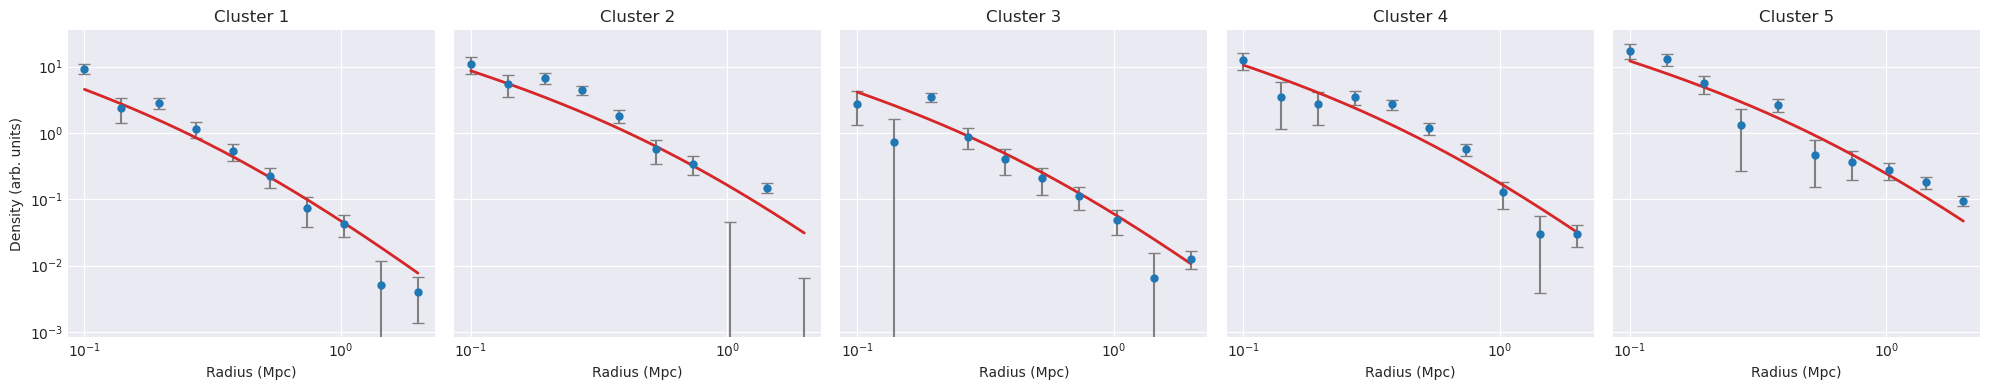

In [10]:
import numpy as np
import matplotlib.pyplot as plt

# --- NFW-like profile function ---
def nfw_profile(r, rho0, rs):
    return rho0 / ((r/rs) * (1 + r/rs)**2)

# --- Setup figure with 5 subplots ---
fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharey=True)

rng = np.random.default_rng(123)

for i, ax in enumerate(axes):
    # Radii for data points (log-spaced)
    r = np.logspace(-1, 0.3, 10)   # 0.1 to ~2

    # True parameters for this mock cluster
    rho0_true = rng.uniform(1.0, 3.0)
    rs_true = rng.uniform(0.3, 0.8)

    # Smooth model curve
    r_model = np.logspace(-1, 0.3, 300)
    y_model = nfw_profile(r_model, rho0_true, rs_true)

    # Data with *larger* noise and scatter
    y_true = nfw_profile(r, rho0_true, rs_true)

    # Larger fractional errors
    y_err = 0.35 * y_true

    # Add stronger scatter to the observed points
    y_obs = y_true + rng.normal(0, 0.5 * y_true) + rng.normal(0, y_err)

    # Plot data with error bars
    ax.errorbar(
        r, y_obs, yerr=y_err,
        fmt="o", markersize=5,
        color="tab:blue", ecolor="gray",
        capsize=4, label="Data"
    )

    # Plot model curve
    ax.plot(
        r_model, y_model,
        color="tab:red", lw=2,
        label="NFW model"
    )

    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(f"Cluster {i+1}")
    ax.set_xlabel("Radius (Mpc)")

axes[0].set_ylabel("Density (arb. units)")
plt.tight_layout()
plt.show()


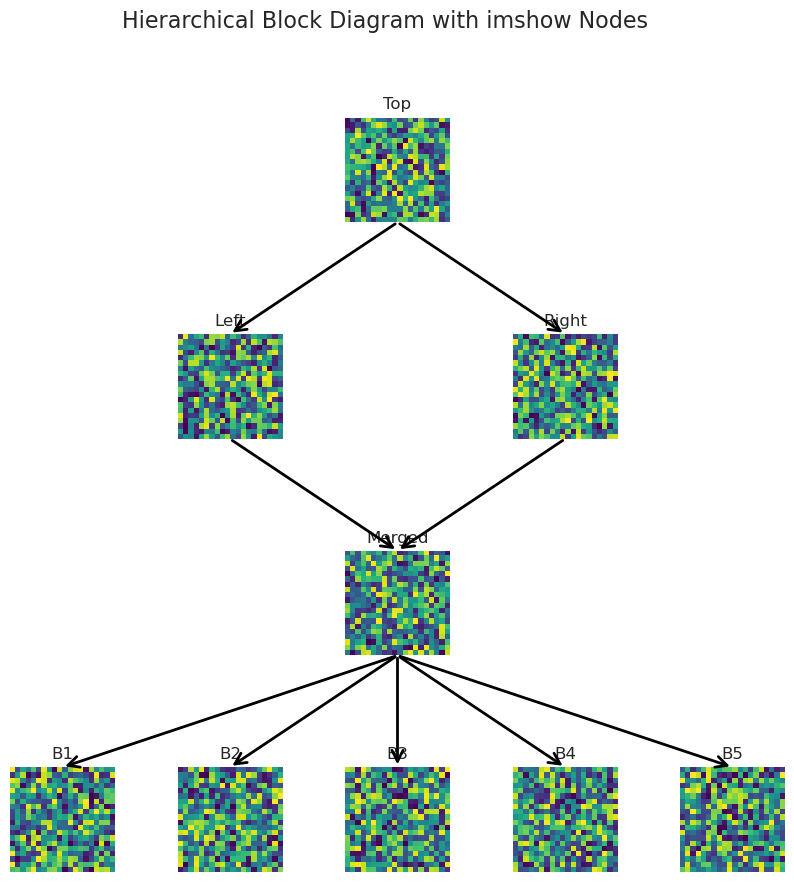

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch
import matplotlib.gridspec as gridspec

fig = plt.figure(figsize=(10, 10))

# Grid layout: 4 rows, 5 columns
gs = gridspec.GridSpec(
    4, 5,
    height_ratios=[1, 1, 1, 1],
    wspace=0.6,
    hspace=0.8
)

axes = {}

# --- Top block (center) ---
axes['top'] = fig.add_subplot(gs[0, 2])
axes['top'].imshow(np.random.random((20, 20)), cmap='viridis', origin='lower')
axes['top'].set_title("Top")
axes['top'].set_xticks([])
axes['top'].set_yticks([])

# --- Second row: two branches ---
axes['left'] = fig.add_subplot(gs[1, 1])
axes['right'] = fig.add_subplot(gs[1, 3])

for key in ['left', 'right']:
    axes[key].imshow(np.random.random((20, 20)), cmap='viridis', origin='lower')
    axes[key].set_title(key.capitalize())
    axes[key].set_xticks([])
    axes[key].set_yticks([])

# --- Third row: merged block ---
axes['middle'] = fig.add_subplot(gs[2, 2])
axes['middle'].imshow(np.random.random((20, 20)), cmap='viridis', origin='lower')
axes['middle'].set_title("Merged")
axes['middle'].set_xticks([])
axes['middle'].set_yticks([])

# --- Bottom row: five branches ---
bottom_keys = ['b1', 'b2', 'b3', 'b4', 'b5']
for i, key in enumerate(bottom_keys):
    axes[key] = fig.add_subplot(gs[3, i])
    axes[key].imshow(np.random.random((20, 20)), cmap='viridis', origin='lower')
    axes[key].set_title(key.upper())
    axes[key].set_xticks([])
    axes[key].set_yticks([])

# --- Arrow helper ---
def connect(ax1, ax2):
    fig.canvas.draw()
    b1 = ax1.get_position()
    b2 = ax2.get_position()

    arrow = FancyArrowPatch(
        ((b1.x0 + b1.x1)/2, b1.y0),     # bottom center of ax1
        ((b2.x0 + b2.x1)/2, b2.y1),     # top center of ax2
        arrowstyle='->',
        mutation_scale=20,
        linewidth=2,
        color='black'
    )
    fig.add_artist(arrow)

# --- Connections ---
connect(axes['top'], axes['left'])
connect(axes['top'], axes['right'])

connect(axes['left'], axes['middle'])
connect(axes['right'], axes['middle'])

for key in bottom_keys:
    connect(axes['middle'], axes[key])

plt.suptitle("Hierarchical Block Diagram with imshow Nodes", fontsize=16)
plt.show()

In [ ]:
import matplotlib.pyplot as plt

img = plt.imread("image.png")
print(img.shape)
